In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/urjagajera12/diabetes/diabetes (2).csv


In [2]:
data = pd.read_csv("/kaggle/input/datasets/urjagajera12/diabetes/diabetes (2).csv")
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,10,168,77,0,0,37.7,0.859,51,1
1,2,105,63,11,0,30.5,0.976,45,0
2,2,129,65,16,14,35.0,1.033,51,1
3,4,144,74,34,0,35.1,0.872,59,1
4,2,169,66,31,0,38.4,0.912,52,1


In [3]:
import matplotlib 
matplotlib.use("Agg") #to store the plot in backend first then show us 
import matplotlib.pyplot as plt

In [4]:
np.random.seed(42) #np.random.rand(42 (this is just a number)) this command will give random value everytime we run but in seed it will chose random value first but then while runing it will be same vlaues
BLUE, GOLD, RED, NAVY = "#0070C0", "#F2A900", "#C0504D", "#21295C"

In [5]:
df = pd.read_csv("/kaggle/input/datasets/urjagajera12/diabetes/diabetes (2).csv")
df.head()
df.shape

(768, 9)

In [6]:
df.columns


Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [7]:
FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin","BMI", "DiabetesPedigreeFunction", "Age"]
TARGET = "Outcome"

In [8]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [9]:
print(df["Glucose"].eq(0).sum())
print(df["BloodPressure"].eq(0).sum())
print(df["SkinThickness"].eq(0).sum())
print(df["Insulin"].eq(0).sum())
print(df["BMI"].eq(0).sum())

7
38
230
376
10


In [10]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zeros treated as missing (before fixing):")
for c in zero_as_missing:
    print(f"  {c:15s}: {(df[c] == 0).sum()}")

for c in zero_as_missing:
    median = df.loc[df[c] != 0, c].median()   # median of the non-zero values
    df[c] = df[c].replace(0, median)          # fill the zeros
print("-> Replaced all such zeros with each column's median.\n")

Zeros treated as missing (before fixing):
  Glucose        : 7
  BloodPressure  : 38
  SkinThickness  : 230
  Insulin        : 376
  BMI            : 10
-> Replaced all such zeros with each column's median.



In [11]:
print(df["Glucose"].eq(0).sum())  
print(df["BloodPressure"].eq(0).sum())
print(df["SkinThickness"].eq(0).sum())
print(df["Insulin"].eq(0).sum())
print(df["BMI"].eq(0).sum())

0
0
0
0
0


In [12]:
X = df[FEATURES].values.astype(float)
y = df[TARGET].values.astype(float)

In [13]:
def train_test_split(X, y, test_ratio=0.25, seed=42):
    rng = np.random.default_rng(seed)
    idx0 = np.where(y == 0)[0]; 
    idx1 = np.where(y == 1)[0]
    rng.shuffle(idx0); rng.shuffle(idx1)
    n0 = int(len(idx0) * test_ratio); n1 = int(len(idx1) * test_ratio)
    test_idx  = np.concatenate([idx0[:n0], idx1[:n1]])
    train_idx = np.concatenate([idx0[n0:], idx1[n1:]])
    rng.shuffle(test_idx); rng.shuffle(train_idx)
    
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y)
print("Train:", X_train_raw.shape[0], " Test:", X_test_raw.shape[0], "\n")

Train: 577  Test: 191 



In [14]:
mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

In [15]:
def add_bias(A):
    return np.hstack([np.ones((A.shape[0], 1)), A])
X_train_b = add_bias(X_train)
X_test_b  = add_bias(X_test)

In [16]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z)) #sigmoid function

In [17]:
def log_loss(X, y, w):
    m=len(y)
    p=sigmoid(X @ w)
    eps = 1e-9
    return -(1/m) * np.sum(y*np.log(p+eps) + (1-y)*np.log(1-p+eps))

In [18]:
def train_logistic(X, y, alpha=0.1, n_iters=3000, class_weight=None):
   # """class_weight = (w0, w1) optionally up-weights the rare class."""
    m, n = X.shape
    w = np.zeros(n)
    history = []
    # per-sample weight: 1.0 normally, or the class weight if provided
    if class_weight is None:
        sample_w = np.ones(m)
    else:
        sample_w = np.where(y == 1, class_weight[1], class_weight[0])
    for _ in range(n_iters):
        p = sigmoid(X @ w)
        grad = (1/m) * (X.T @ (sample_w * (p - y)))
        w = w - alpha * grad
        history.append(log_loss(X, y, w))
    return w, history


In [19]:
w, cost_history = train_logistic(X_train_b, y_train, alpha=0.1, n_iters=3000)
print("Training done. Final log-loss:", round(np.mean(cost_history[-1]), 4), "\n")

Training done. Final log-loss: 0.2014 



In [20]:
def predict_proba(X, w):
    return sigmoid(X @ w)

def predict_label(X, w, threshold=0.5):
    return (predict_proba(X, w) >= threshold).astype(int)

proba_test = predict_proba(X_test_b, w)
pred_test  = predict_label(X_test_b, w)

In [21]:
def confusion_matrix(y_true, y_pred):
    TP = int(np.sum((y_pred == 1) & (y_true == 1)))
    TN = int(np.sum((y_pred == 0) & (y_true == 0)))
    FP = int(np.sum((y_pred == 1) & (y_true == 0)))
    FN = int(np.sum((y_pred == 0) & (y_true == 1)))
    return TP, TN, FP, FN

In [22]:
def metrics(y_true, y_pred):
    TP, TN, FP, FN = confusion_matrix(y_true, y_pred)
    accuracy  = (TP + TN) / (TP + TN + FP + FN)
    precision = TP / (TP + FP) if (TP + FP) else 0.0
    recall    = TP / (TP + FN) if (TP + FN) else 0.0
    f1 = (2*precision*recall / (precision+recall)) if (precision+recall) else 0.0
    return dict(accuracy=accuracy, precision=precision, recall=recall,
                f1=f1, TP=TP, TN=TN, FP=FP, FN=FN)

In [23]:
print("test matrix: \n",metrics(y_test, pred_test))

test matrix: 
 {'accuracy': 0.9162303664921466, 'precision': 0.9322033898305084, 'recall': 0.8208955223880597, 'f1': 0.873015873015873, 'TP': 55, 'TN': 120, 'FP': 4, 'FN': 12}


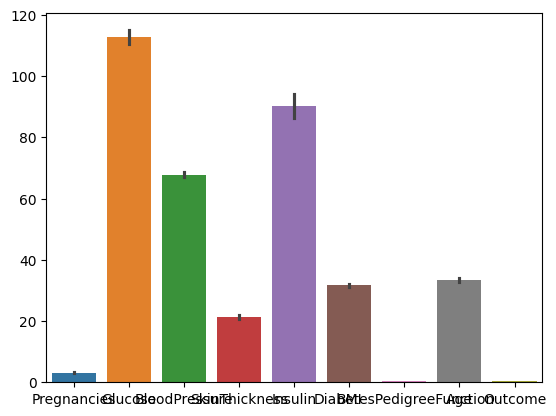

In [24]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
sns.barplot(data=df )
plt.show()

                          Pregnancies   Glucose  BloodPressure  SkinThickness  \
Pregnancies                  1.000000  0.212120       0.110852       0.051787   
Glucose                      0.212120  1.000000       0.282597       0.246556   
BloodPressure                0.110852  0.282597       1.000000       0.052340   
SkinThickness                0.051787  0.246556       0.052340       1.000000   
Insulin                      0.030097  0.180397       0.053230       0.060460   
BMI                          0.134147  0.379825       0.167109       0.140358   
DiabetesPedigreeFunction     0.096632  0.404225       0.091457       0.128111   
Age                          0.087422  0.457278       0.171320       0.123470   
Outcome                      0.241315  0.668278       0.222955       0.212566   

                           Insulin       BMI  DiabetesPedigreeFunction  \
Pregnancies               0.030097  0.134147                  0.096632   
Glucose                   0.180397  0.379

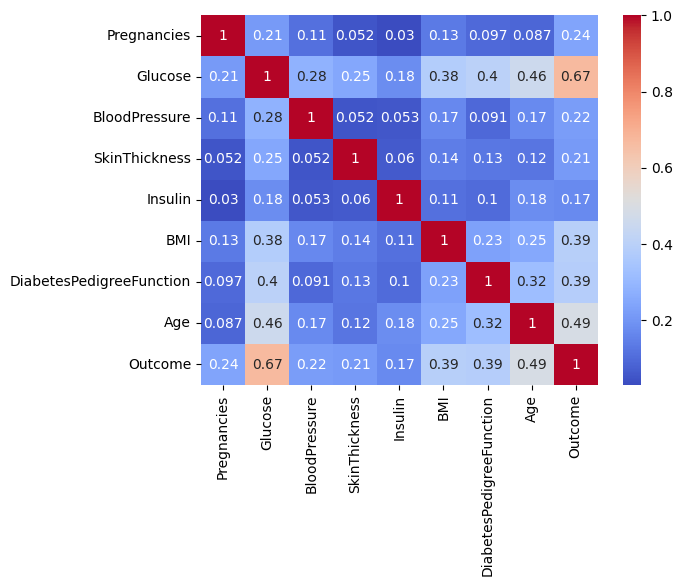

In [25]:
print(data.corr())
sns.heatmap(data=data.corr(), annot=True, cmap='coolwarm')
plt.show()

In [26]:
print("Q1. to find strongest influencing attributes")

# Because features are standardised, larger |weight| = stronger influence.
influence = sorted(zip(FEATURES, w[1:]), key=lambda t: abs(t[1]), reverse=True)
for name, weight in influence:
    direction = "raises risk" if weight > 0.99 else "lowers risk"
    print(f"  {name:26s} weight = {weight:+.3f}  ({direction})")

Q1. to find strongest influencing attributes
  Glucose                    weight = +3.696  (raises risk)
  Age                        weight = +1.122  (raises risk)
  BMI                        weight = +1.033  (raises risk)
  Pregnancies                weight = +0.645  (lowers risk)
  DiabetesPedigreeFunction   weight = +0.406  (lowers risk)
  Insulin                    weight = +0.286  (lowers risk)
  SkinThickness              weight = -0.166  (lowers risk)
  BloodPressure              weight = +0.060  (lowers risk)


In [27]:

print("Q2. for class balance we can check both fiabetic and non-diabetic ")
n_pos = int(np.sum(y == 1)); n_neg = int(np.sum(y == 0))
print(f"  Non-diabetic (0): {n_neg}  ({n_neg/len(y)*100:.1f}%)")
print(f"  Diabetic     (1): {n_pos}  ({n_pos/len(y)*100:.1f}%)")


Q2. for class balance we can check both fiabetic and non-diabetic 
  Non-diabetic (0): 499  (65.0%)
  Diabetic     (1): 269  (35.0%)


In [28]:
print("Q3. Performance from confusion matrix")
base = metrics(y_test, pred_test)
print(f"  Confusion matrix:  TP={base['TP']}  FP={base['FP']}")
print(f"                     FN={base['FN']}  TN={base['TN']}")
print(f"  Accuracy : {base['accuracy']:.3f}")
print(f"  Precision: {base['precision']:.3f}")
print(f"  Recall   : {base['recall']:.3f} ")
print(f"  F1-score : {base['f1']:.3f}\n")

Q3. Performance from confusion matrix
  Confusion matrix:  TP=55  FP=4
                     FN=12  TN=120
  Accuracy : 0.916
  Precision: 0.932
  Recall   : 0.821 
  F1-score : 0.873



In [29]:
print("Q5. 'Borderline' patients: labelled non-diabetic but high predicted risk")

# among test patients whose TRUE label is 0, find the highest predicted risk
mask_true_neg = (y_test == 0)
neg_probs = proba_test[mask_true_neg]
order = np.argsort(neg_probs)[::-1][:5]           # top 5 riskiest "non-diabetics"
neg_positions = np.where(mask_true_neg)[0][order]

print("  Top 5 non-diabetic patients by predicted risk:")
print("   risk%   Glucose  BMI   Age  Pedigree")

for pos in neg_positions:
    raw = X_test_raw[pos]
    print(f"    {proba_test[pos]*100:5.1f}   {raw[1]:6.0f}  {raw[5]:4.1f}  {raw[7]:3.0f}   {raw[6]:.2f}")
print("  Insight: these people resemble diabetics on key markers (high glucose/")
print("  BMI). They are prime candidates for early screening and lifestyle advice,")
print("  even though today's label says non-diabetic.\n")

Q5. 'Borderline' patients: labelled non-diabetic but high predicted risk
  Top 5 non-diabetic patients by predicted risk:
   risk%   Glucose  BMI   Age  Pedigree
     81.9      133  33.8   34   1.05
     76.1      110  39.8   34   0.91
     66.8      123  45.2   34   0.08
     55.6      137  30.1   33   0.21
     45.6      127  40.2   32   0.32
  Insight: these people resemble diabetics on key markers (high glucose/
  BMI). They are prime candidates for early screening and lifestyle advice,
  even though today's label says non-diabetic.



In [30]:
# Q7. VISUALISATIONS THAT EXPLAIN PERFORMANCE

# (a) learning curve

plt.figure(figsize=(6.5, 3.6))
plt.plot(cost_history, color=BLUE, lw=2)
plt.title("Q7a: Learning curve (log-loss vs iteration)")
plt.xlabel("iteration")
plt.ylabel("log-loss")
plt.tight_layout()
plt.savefig("q7_learning_curve.png", facecolor="white")
plt.close()

In [31]:
# (b) confusion matrix heatmap (baseline)

def plot_confusion(m, title, path):
    mat = np.array([[m['TN'], m['FP']], [m['FN'], m['TP']]])

    plt.figure(figsize=(4.6, 4.2))
    plt.imshow(mat, cmap="Blues")

    for i in range(2):
        for j in range(2):
            plt.text(j, i, mat[i, j], ha="center", va="center",
                     fontsize=16, color="black")

    plt.xticks([0, 1], ["Pred 0", "Pred 1"])
    plt.yticks([0, 1], ["True 0", "True 1"])
    plt.title(title)
    plt.tight_layout()
    plt.savefig(path, facecolor="white")
    plt.close()

plot_confusion(base, "Q7b: Confusion matrix (baseline)", "q7_confusion.png")

In [32]:
# (c) probability distribution by true class

plt.figure(figsize=(6.5, 3.8))

plt.hist(
    proba_test[y_test == 0],
    bins=15,
    alpha=0.7,
    label="Non-diabetic",
    color=BLUE
)

plt.hist(
    proba_test[y_test == 1],
    bins=15,
    alpha=0.7,
    label="Diabetic",
    color=GOLD
)

plt.axvline(0.5, color=RED, ls="--", label="0.5 threshold")

plt.title("Q7c: Predicted risk by true class")
plt.xlabel("predicted probability of diabetes")
plt.ylabel("count")
plt.legend()
plt.tight_layout()
plt.savefig("q7_prob_hist.png", facecolor="white")
plt.close()

In [33]:
# (d) ROC curve (from scratch)

def roc_points(y_true, scores):
    thresholds = np.linspace(0, 1, 101)
    tprs, fprs = [], []

    P = np.sum(y_true == 1)
    Nn = np.sum(y_true == 0)

    for t in thresholds:
        pred = (scores >= t).astype(int)

        TP = np.sum((pred == 1) & (y_true == 1))
        FP = np.sum((pred == 1) & (y_true == 0))

        tprs.append(TP / P if P else 0)
        fprs.append(FP / Nn if Nn else 0)

    return np.array(fprs), np.array(tprs)

fpr, tpr = roc_points(y_test, proba_test)

# area under the curve via the trapezoidal rule

_x, _y = fpr[::-1], tpr[::-1]

auc = float(
    np.sum(
        (_x[1:] - _x[:-1]) *
        (_y[1:] + _y[:-1]) / 2.0
    )
)

plt.figure(figsize=(5, 4.6))

plt.plot(
    fpr,
    tpr,
    color=BLUE,
    lw=2,
    label=f"model (AUC={auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    color=GOLD,
    ls="--",
    label="random guess"
)

plt.title("Q7d: ROC curve")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.legend()
plt.tight_layout()
plt.savefig("q7_roc.png", facecolor="white")
plt.close()